In [1]:
from tbparse import SummaryReader
import matplotlib.pyplot as plt

In [2]:
log_dir = "/data/yinbin/google-research/dpok/online_model/img_reward_0/pre_train/single_prompt/Four_wolves_in_the_park./p_lr0.0003_s1_pb5_gb1_n10_g100_l4_kl0.01_re10.0_v_lr0.0001_b256_s5"
reader = SummaryReader(log_dir)
df = reader.scalars
print(df)

      step         tag     value
0        0   grad norm  0.032729
1        1   grad norm  0.031033
2        2   grad norm  0.027733
3        3   grad norm  0.029487
4        4   grad norm  0.025115
...    ...         ...       ...
5995   995  value_loss  0.027591
5996   996  value_loss  0.028410
5997   997  value_loss  0.055464
5998   998  value_loss  0.056066
5999   999  value_loss  0.026411

[6000 rows x 3 columns]


In [3]:
df.to_csv('count_dpok0.csv', index=False)

In [5]:
# all tags in tb
df['tag'].unique()

array(['grad norm', 'kl', 'p_loss', 'ratio', 'train_reward', 'value_loss'],
      dtype=object)

In [13]:
grad_norm = df[df["tag"] == "grad norm"]
kl = df[df["tag"] == "kl"]
train_reward = df[df["tag"] == "train_reward"]

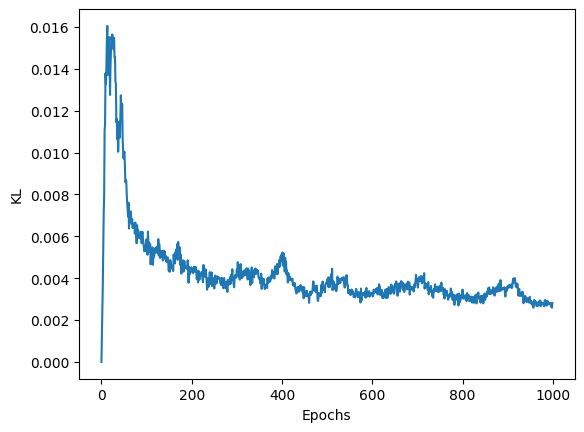

In [50]:
plt.plot(kl["step"], kl["value"])
plt.xlabel("Epochs")
plt.ylabel("KL")
# plt.title("KL vs. Step")
output_file = log_dir + "/figures/kl.png"
plt.savefig(output_file, dpi=300)

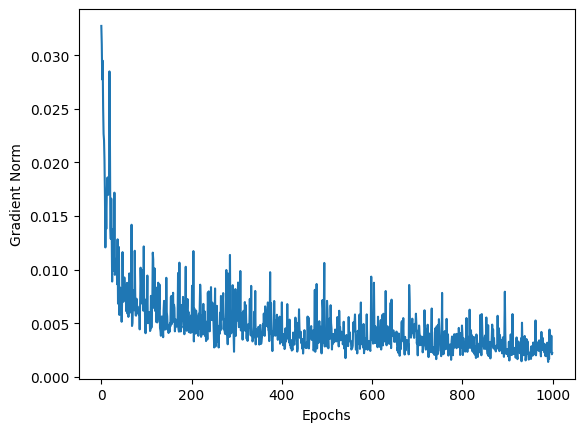

In [52]:
plt.plot(grad_norm["step"], grad_norm["value"])
plt.xlabel("Epochs")
plt.ylabel("Gradient Norm")
# plt.title("Gradient norm vs. Step")
output_file = log_dir + "/figures/grad_norm.png"
plt.savefig(output_file, dpi=300)

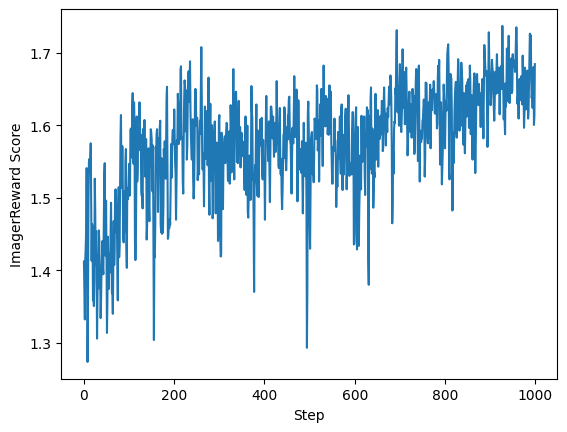

In [54]:
plt.plot(train_reward["step"], train_reward["value"])
plt.xlabel("Step")
plt.ylabel("ImagerReward Score")
# plt.title("train reward vs. Step")
output_file = log_dir + "/figures/reward.png"
plt.savefig(output_file, dpi=300)

In [38]:
baseline="/data/yinbin/google-research/dpok/online_model/img_reward_0/pre_train/single_prompt/Four_wolves_in_the_park./p_lr1e-05_s10_pb5_gb1_n10_g10_l4_kl0.01_re10.0_v_lr0.0001_b256_s5_dpok"

In [40]:
reader = SummaryReader(baseline)
df_baseline = reader.scalars
print(df_baseline)

       step         tag     value
0         0   grad norm  0.006941
1         0   grad norm  0.014622
2         0   grad norm  0.021806
3         0   grad norm  0.029359
4         0   grad norm  0.037016
...     ...         ...       ...
50995   995  value_loss  0.030010
50996   996  value_loss  0.028460
50997   997  value_loss  0.027369
50998   998  value_loss  0.082789
50999   999  value_loss  0.087584

[51000 rows x 3 columns]


In [41]:
baseline_grad_norm = df_baseline[df_baseline["tag"] == "grad norm"]
baseline_kl = df_baseline[df_baseline["tag"] == "kl"]
baseline_train_reward = df_baseline[df_baseline["tag"] == "train_reward"]

In [47]:
baseline_kl.head(20)

,step,tag,value
10000,0,kl,0.000000
10001,0,kl,0.000002
10002,0,kl,0.000004
10003,0,kl,0.000006
10004,0,kl,0.000010
10005,0,kl,0.000013
10006,0,kl,0.000016
10007,0,kl,0.000020
10008,0,kl,0.000023
10009,0,kl,0.000027


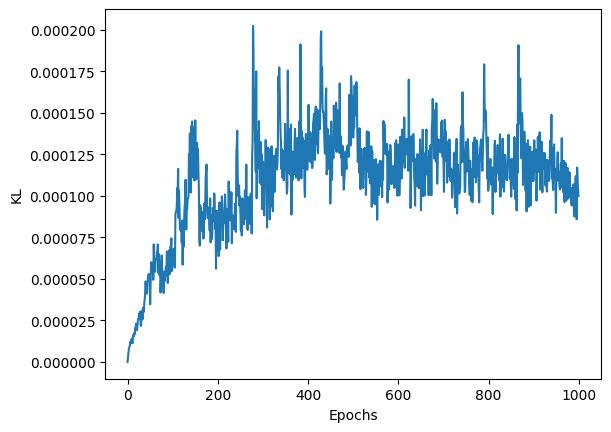

In [48]:
baseline_kl_downsampled = baseline_kl.iloc[::10, :]
plt.plot(baseline_kl_downsampled["step"], baseline_kl_downsampled["value"])
plt.xlabel("Epochs")
plt.ylabel("KL")
# plt.title("KL vs. Step")
output_file = baseline + "/figures/kl.png"
# plt.savefig(output_file, dpi=300)

In [43]:
plt.clear()

AttributeError: module 'matplotlib.pyplot' has no attribute 'clear'